# Агент-художник: анализ экспериментов

Художники-агенты уточняют детали картины у арт-эксперта, пишут промпты для генераторов и
переделывают работу по его критике. Здесь — разбор четырёх экспериментов:

1. **Общий контекст** — помогает ли художникам видеть вопросы друг друга (`shared`) или нет (`isolated`).
2. **Культурная асимметрия** — один генератор (Yandex ART) с русским и английским промптом на культурных и нейтральных идеях.
3. **«Нейро-Крокодил»** — поговорки только изображением; как английский промпт их переводит.
4. **«Испорченный телефон»** — картина → пересказ → картина по пересказу → …

Художники: **A** — SDXL-Turbo, промпт на английском; **B** — Yandex ART, на русском; **C** — Yandex ART, на английском.

Ноутбук только читает готовые прогоны из `runs/` и кеши анализа — моделей не вызывает, перезапуск бесплатный.
Недостающее считается командами `agent-artist-experiment recover / translation / telephone` (см. README).

In [1]:
from io import BytesIO
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, Markdown, display
from PIL import Image as PILImage

from agent_artist import analysis
from agent_artist.summary import summarize

RUNS = Path("runs")
pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def show(path, max_width=1400):
    """Показать картинку, уменьшенную до max_width и сжатую в JPEG, чтобы ноутбук оставался лёгким."""
    if not Path(path).exists():
        print(f"Нет файла {path} — эксперимент ещё не запускался")
        return
    picture = PILImage.open(path).convert("RGB")
    picture.thumbnail((max_width, max_width * 4))
    buffer = BytesIO()
    picture.save(buffer, format="JPEG", quality=82)
    display(Image(data=buffer.getvalue(), format="jpeg"))

## Что есть в данных

In [2]:
scores = analysis.scores_frame([RUNS])
experiments = scores.assign(experiment=scores.run.str.split("/").str[1])
(experiments.groupby("experiment")
 .agg(прогонов=("run", "nunique"), картин=("score", "size"), отказов=("refused", "sum"),
      идей=("idea", "nunique"))
 .sort_values("картин", ascending=False))

,прогонов,картин,отказов,идей
experiment,,,,
culture,10,57,11,5
experiment_lighthouse,4,24,0,1
20261013_221703,1,16,0,1
proverbs,1,6,1,1
20261013_203512,1,4,0,1
20261013_204957,1,2,0,1


## 1. Общий контекст: shared против isolated

Одна идея («Маяк в шторм»), по несколько повторов в каждом режиме, три итерации без ранней остановки.
Оценки — от эксперта, который видит картину. Ниже — средняя оценка по итерациям.

  ! Пропускаю runs/experiment_lighthouse/03_isolated/log.json: нет оценок или старый формат лога
  ! Пропускаю runs/experiment_lighthouse/03_shared/log.json: нет оценок или старый формат лога


## Маяк в шторм — эксперт видит картинку

| Художник | Режим | Прогонов | Первая | Последняя | Лучшая | Прирост |
|---|---|---|---|---|---|---|
| A (local, анг) | isolated | 2 | 4.5 ± 2.1 | 4.0 ± 0.0 | 5.0 ± 1.4 | -0.5 ± 2.1 |
| A (local, анг) | shared | 2 | 4.0 ± 0.0 | 5.5 ± 0.7 | 5.5 ± 0.7 | 1.5 ± 0.7 |
| B (yandex_art, рус) | isolated | 2 | 6.5 ± 0.7 | 6.0 ± 2.8 | 7.5 ± 0.7 | -0.5 ± 3.5 |
| B (yandex_art, рус) | shared | 2 | 7.0 ± 1.4 | 7.0 ± 0.0 | 8.0 ± 0.0 | 0.0 ± 1.4 |

Средняя оценка по итерациям:

| Художник | Режим | 1 | 2 | 3 |
|---|---|---|---|---|
| A (local, анг) | isolated | 4.5 ± 2.1 | 3.5 ± 0.7 | 4.0 ± 0.0 |
| A (local, анг) | shared | 4.0 ± 0.0 | 3.5 ± 0.7 | 5.5 ± 0.7 |
| B (yandex_art, рус) | isolated | 6.5 ± 0.7 | 6.0 ± 0.0 | 6.0 ± 2.8 |
| B (yandex_art, рус) | shared | 7.0 ± 1.4 | 7.0 ± 1.4 | 7.0 ± 0.0 |


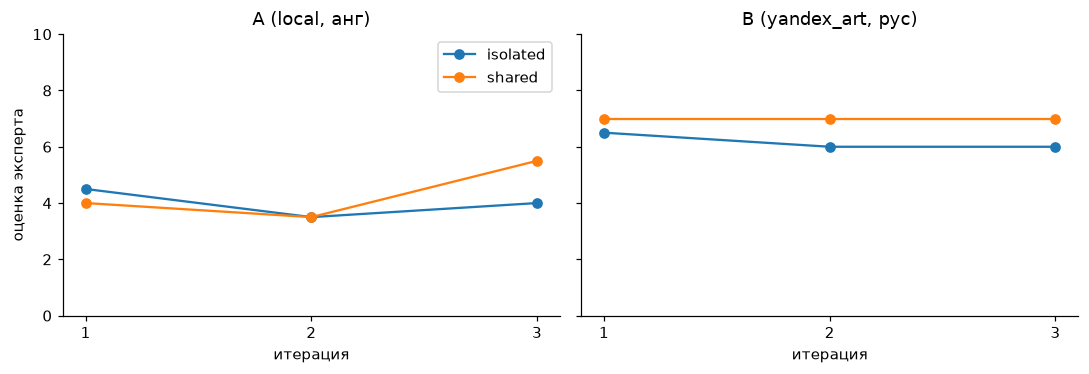

In [3]:
LIGHTHOUSE = RUNS / "experiment_lighthouse"
display(Markdown(summarize([LIGHTHOUSE])))

lighthouse = scores[scores.run.str.startswith(str(LIGHTHOUSE))]
if not lighthouse.empty:
    fig, axes = plt.subplots(1, lighthouse.artist.nunique(), figsize=(10, 3.5), sharey=True)
    for ax, (artist, group) in zip(axes, lighthouse.groupby("artist")):
        for mode, by_mode in group.groupby("mode"):
            means = by_mode.groupby("iteration").score.mean()
            ax.plot(means.index, means.values, marker="o", label=mode)
        ax.set(title=artist, xlabel="итерация", ylim=(0, 10), xticks=sorted(group.iteration.unique()))
    axes[0].set_ylabel("оценка эксперта")
    axes[0].legend()
    plt.tight_layout()

Та же серия глазами **слепого зрителя** («угадай заказ»): он видит только картину и не знает заказа.
`details_conveyed` — доля согласованных с экспертом пунктов, которые действительно видны на картине.

In [4]:
recovery = analysis.recovery_frame([RUNS])
lighthouse_recovery = recovery[recovery.run.str.startswith(str(LIGHTHOUSE))]
if lighthouse_recovery.empty:
    print("Нет recovery.json — запустите: agent-artist-experiment recover runs/experiment_lighthouse")
else:
    display(lighthouse_recovery.pivot_table(index="artist", columns="mode", values="details_conveyed",
                                            aggfunc="mean").style.format("{:.0%}"))

mode,isolated,shared
artist,,
"A (local, анг)",32%,47%
"B (yandex_art, рус)",59%,68%


## 2. Культурная асимметрия

Четыре культурные идеи и две нейтральные, художники A, B, C. Сравнение **B и C** — один генератор,
разные языки промпта: чистый эффект языка. Гипотеза: на культурных идеях разрыв B − C больше, чем на нейтральных.

Отказы модерации Yandex ART (оценка 0) считаются отдельно — это не качество картины, а то, что её не нарисовали.

In [5]:
CULTURE = RUNS / "culture"
CULTURAL_IDEAS = ["Масленица на деревенской площади", "Баба-Яга у избушки на курьих ножках",
                  "Двор хрущёвки зимним вечером", "Мороз и солнце; день чудесный"]
culture = scores[scores.run.str.startswith(str(CULTURE))].copy()
culture["kind"] = culture.idea.map(lambda idea: "культурная" if idea in CULTURAL_IDEAS else "нейтральная")

if culture.empty:
    print("Серия ещё не запускалась: bash experiments/culture_language.sh")
else:
    print("Отказы генератора (картин без изображения):")
    display(culture.pivot_table(index="idea", columns="artist", values="refused", aggfunc="sum"))
    drawn = culture[~culture.refused]
    print("Средняя оценка нарисованных картин:")
    display(drawn.pivot_table(index=["kind", "idea"], columns="artist", values="score",
                              aggfunc="mean").round(1))

Отказы генератора (картин без изображения):


artist,"A (local, анг)","B (yandex_art, рус)","C (yandex_art, анг)"
idea,,,
Баба-Яга у избушки на курьих ножках,0,1,2
Двор хрущёвки зимним вечером,0,2,2
Масленица на деревенской площади,0,2,2
Маяк в шторм,0,0,0
Мороз и солнце; день чудесный,0,0,0


Средняя оценка нарисованных картин:


artist                                           A (local, анг)  \
kind        idea                                                  
культурная  Баба-Яга у избушки на курьих ножках             2.8   
            Двор хрущёвки зимним вечером                    2.8   
            Масленица на деревенской площади                2.8   
            Мороз и солнце; день чудесный                   5.0   
нейтральная Маяк в шторм                                    4.0   

artist                                           B (yandex_art, рус)  \
kind        idea                                                       
культурная  Баба-Яга у избушки на курьих ножках                  4.7   
            Двор хрущёвки зимним вечером                         4.0   
            Масленица на деревенской площади                     5.0   
            Мороз и солнце; день чудесный                        4.8   
нейтральная Маяк в шторм                                         6.7   

artist                                           C (yandex_art, анг)  
kind        idea                                                      
культурная  Баба-Яга у избушки на курьих ножках                  6.0  
            Двор хрущёвки зимним вечером                         7.0  
            Масленица на деревенской площади                     4.5  
            Мороз и солнце; день чудесный                        7.0  
нейтральная Маяк в шторм                                         5.7

**Эффект языка (B − C), средний по идеям:** культурные -1.5, нейтральные +1.0

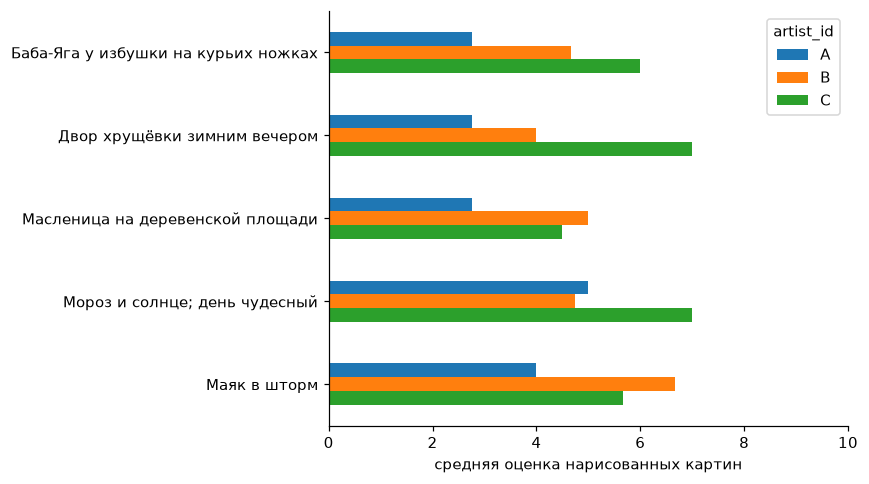

In [6]:
if not culture.empty:
    drawn = culture[~culture.refused]
    by_idea = drawn.pivot_table(index=["kind", "idea"], columns="artist_id", values="score", aggfunc="mean")
    by_idea["B − C"] = by_idea["B"] - by_idea["C"]
    gap = by_idea.groupby(level="kind")["B − C"].mean()
    display(Markdown(f"**Эффект языка (B − C), средний по идеям:** "
                     f"культурные {gap.get('культурная', float('nan')):+.1f}, "
                     f"нейтральные {gap.get('нейтральная', float('nan')):+.1f}"))
    ax = by_idea[["A", "B", "C"]].droplevel("kind").plot.barh(figsize=(8, 4.5), xlim=(0, 10))
    ax.set(xlabel="средняя оценка нарисованных картин", ylabel="")
    ax.invert_yaxis()
    plt.tight_layout()

Узнаёт ли **слепой зритель** идею по картине — та же разбивка, но без вкуса эксперта:

In [7]:
culture_recovery = recovery[recovery.run.str.startswith(str(CULTURE))]
if culture_recovery.empty:
    print("Нет recovery.json — запустите: agent-artist-experiment recover runs/culture")
else:
    display(culture_recovery.pivot_table(index="idea", columns="artist", values="idea_recognized",
                                         aggfunc="mean").style.format("{:.0%}"))

Нет recovery.json — запустите: agent-artist-experiment recover runs/culture


## 3. «Нейро-Крокодил»: поговорки

Художник передаёт поговорку только изображением, без надписей; слепой зритель угадывает.
*Узнана* — по смыслу, в том числе через аналог из другого языка; *названа* — почти дословно.

In [8]:
PROVERBS = RUNS / "proverbs"
proverbs_recovery = recovery[recovery.run.str.startswith(str(PROVERBS))]
if proverbs_recovery.empty:
    print("Нет данных — bash experiments/proverbs.sh, затем agent-artist-experiment recover runs/proverbs")
else:
    table = proverbs_recovery.groupby(["idea", "artist"]).agg(
        узнана=("idea_recognized", "mean"), названа=("idea_named", "mean")).unstack("artist")
    display(table.style.format("{:.0%}"))

Нет данных — bash experiments/proverbs.sh, затем agent-artist-experiment recover runs/proverbs


Как художники с **английским** промптом (A и C) перенесли поговорку: *literal* — дословные образы
(медведь, шкура), *equivalent* — образы английского аналога (цыплята), *meaning* — свои образы для смысла.

In [9]:
translation = analysis.translation_frame([PROVERBS])
if translation.empty:
    print("Нет translation.json — запустите: agent-artist-experiment translation runs/proverbs")
else:
    strategies = translation.pivot_table(index="idea", columns="strategy", values="prompt",
                                         aggfunc="count", fill_value=0)
    ax = strategies.plot.barh(stacked=True, figsize=(8, 4))
    ax.set(xlabel="английских промптов", ylabel="")
    ax.invert_yaxis()
    plt.tight_layout()

Нет translation.json — запустите: agent-artist-experiment translation runs/proverbs


## 4. «Испорченный телефон»

Шаг 0 — картина по идее. Дальше слепой зритель описывает картину, и следующий художник рисует только по
описанию — без идеи, без картины. Судья оценивает сходство каждой картины с исходной идеей (0–10).

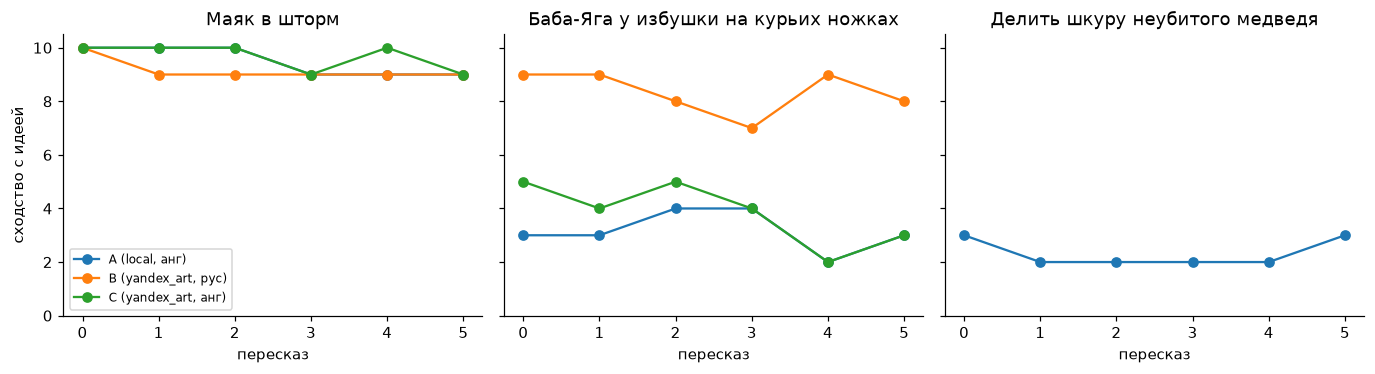

In [10]:
TELEPHONE = RUNS / "telephone"
telephone = analysis.telephone_frame([TELEPHONE])
if telephone.empty:
    print("Нет данных — bash experiments/telephone.sh")
else:
    ideas = telephone.idea.unique()
    fig, axes = plt.subplots(1, len(ideas), figsize=(4.2 * len(ideas), 3.5), sharey=True, squeeze=False)
    for ax, idea in zip(axes[0], ideas):
        for artist, chain in telephone[telephone.idea == idea].groupby("artist"):
            ax.plot(chain.step, chain.similarity, marker="o", label=artist)
        ax.set(title=idea, xlabel="пересказ", ylim=(0, 10.5))
    axes[0][0].set_ylabel("сходство с идеей")
    axes[0][0].legend(fontsize=8)
    plt.tight_layout()

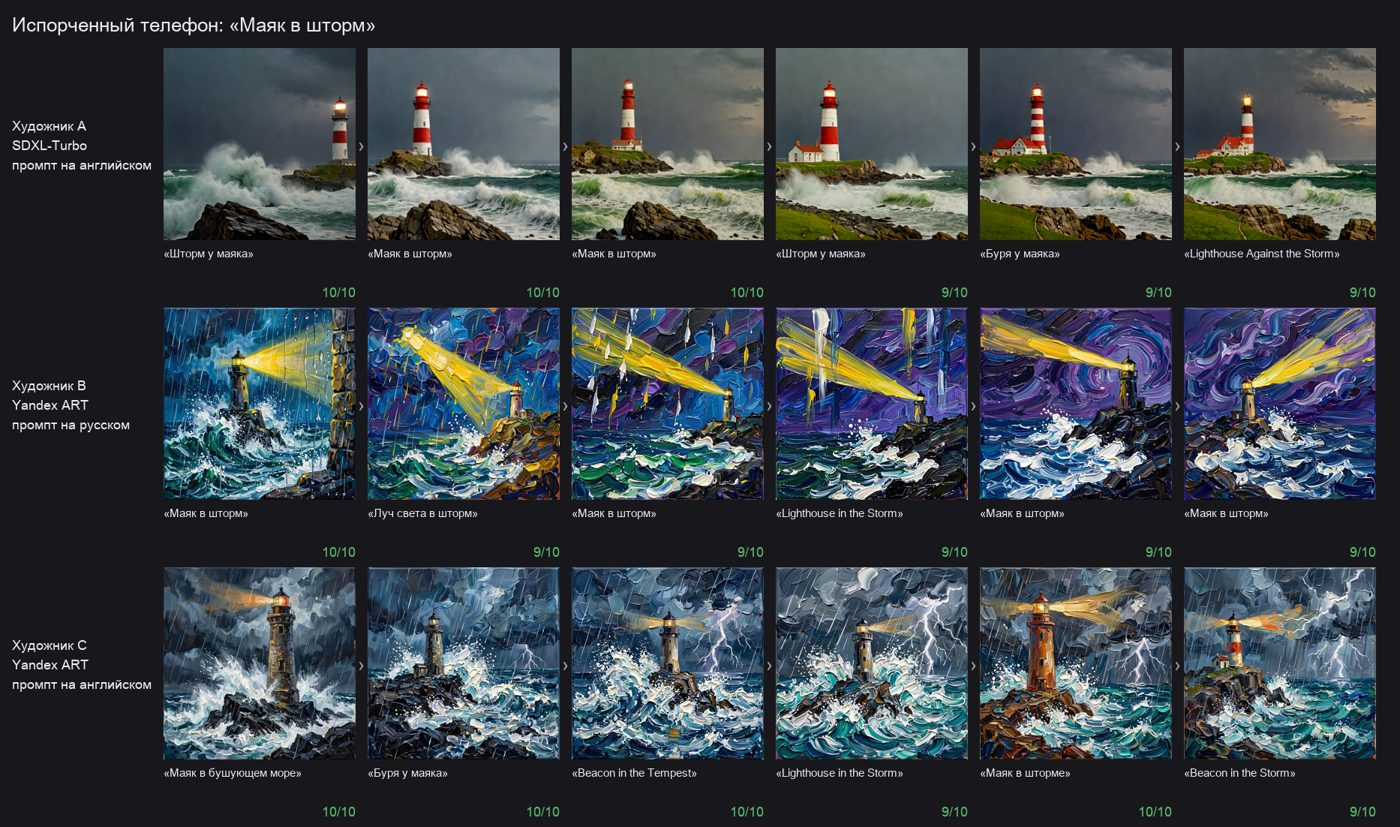

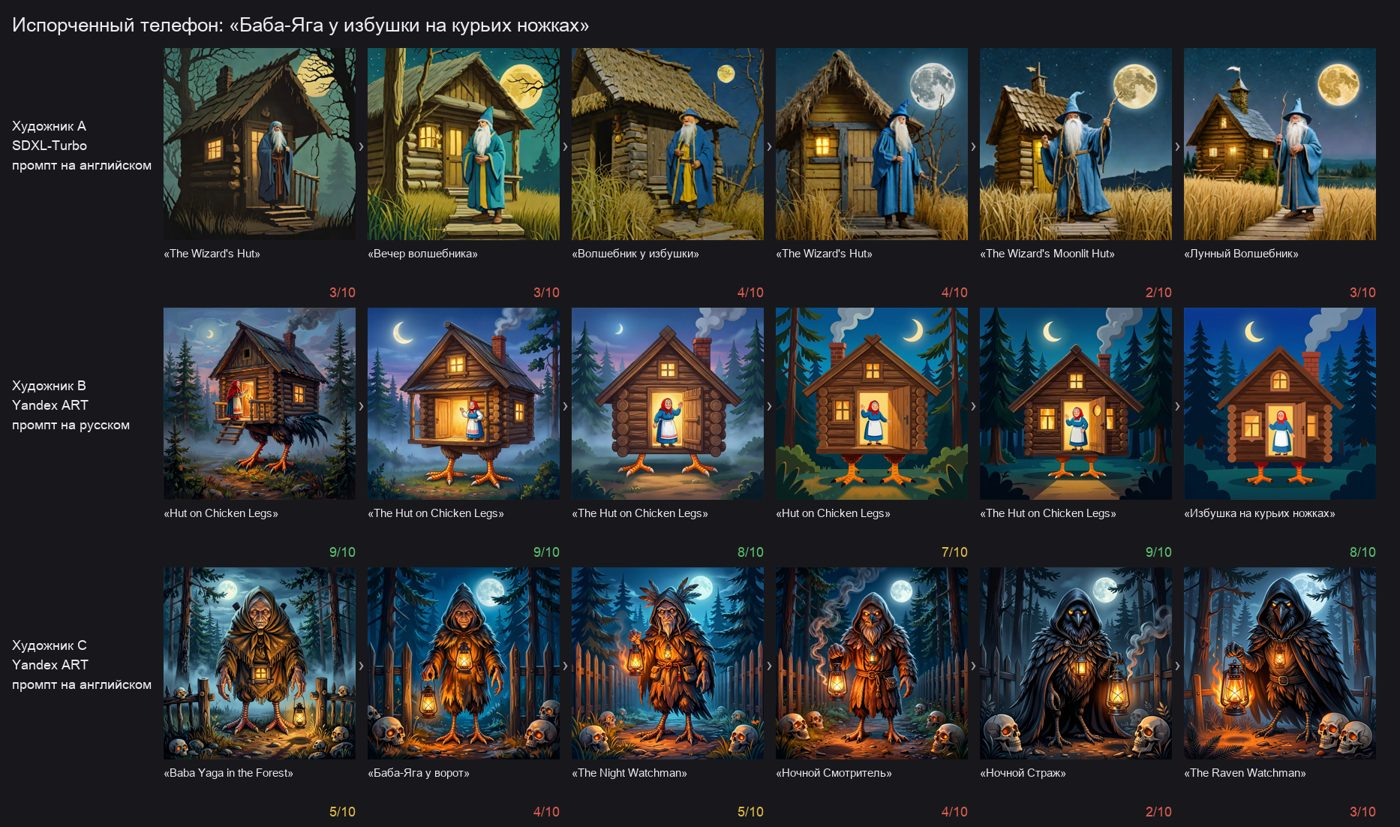

In [11]:
for strip in sorted(TELEPHONE.glob("*/telephone.png")):
    show(strip)

## Галерея

Сетки «художники × итерации» — как картины менялись под критикой эксперта. Анимированные версии —
`timelapse.webp` / `timelapse.gif` в папке каждого прогона.

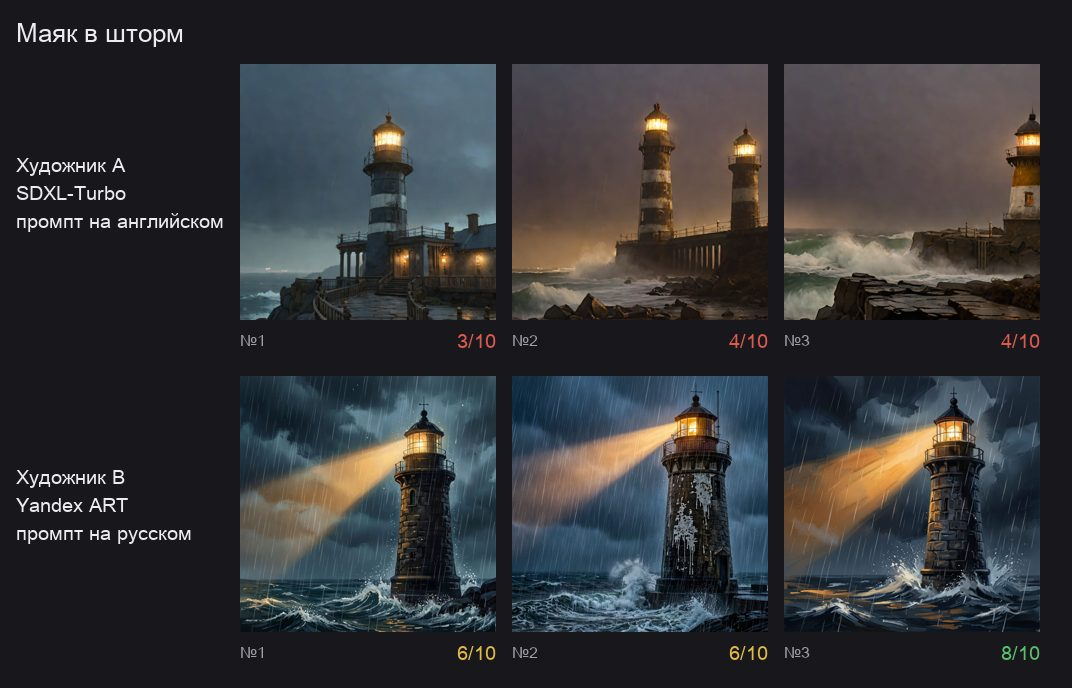

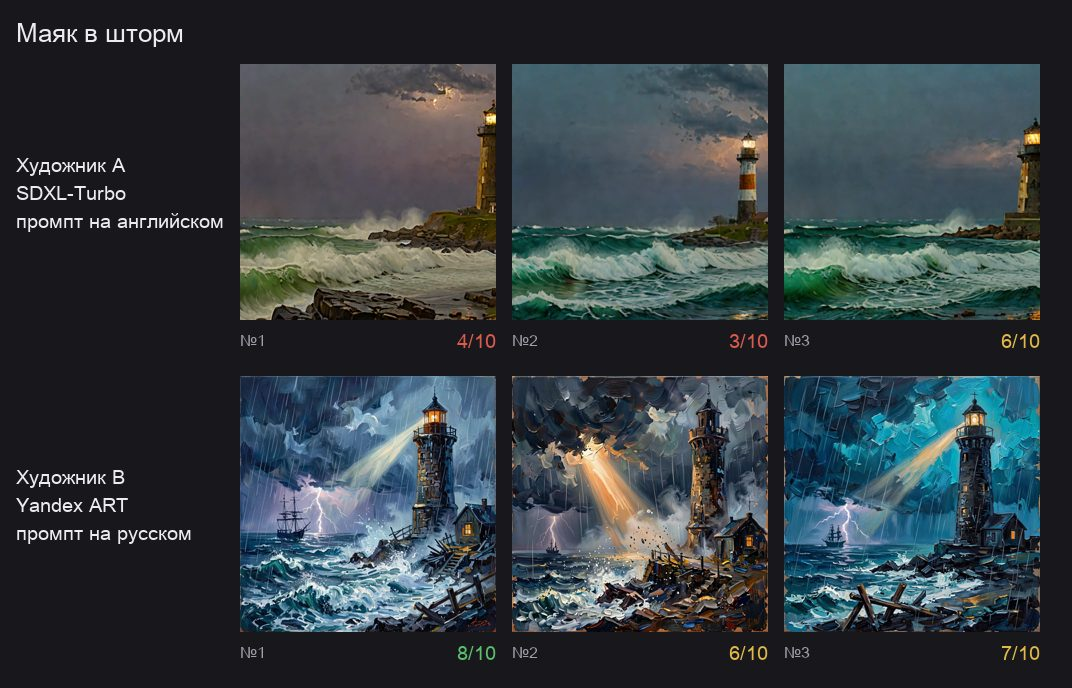

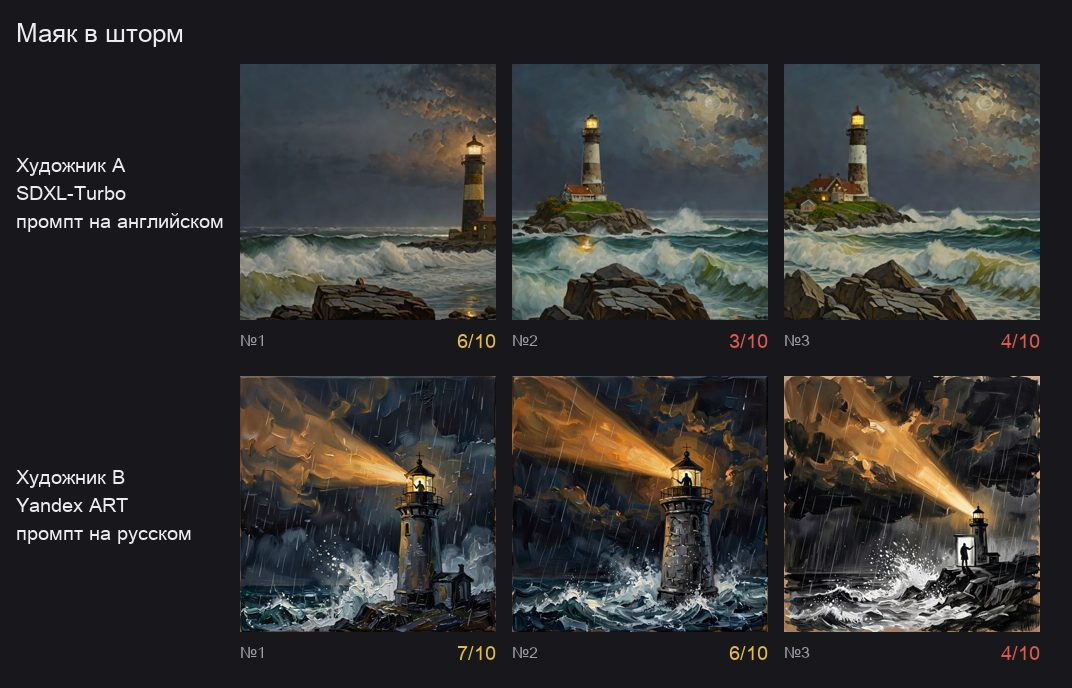

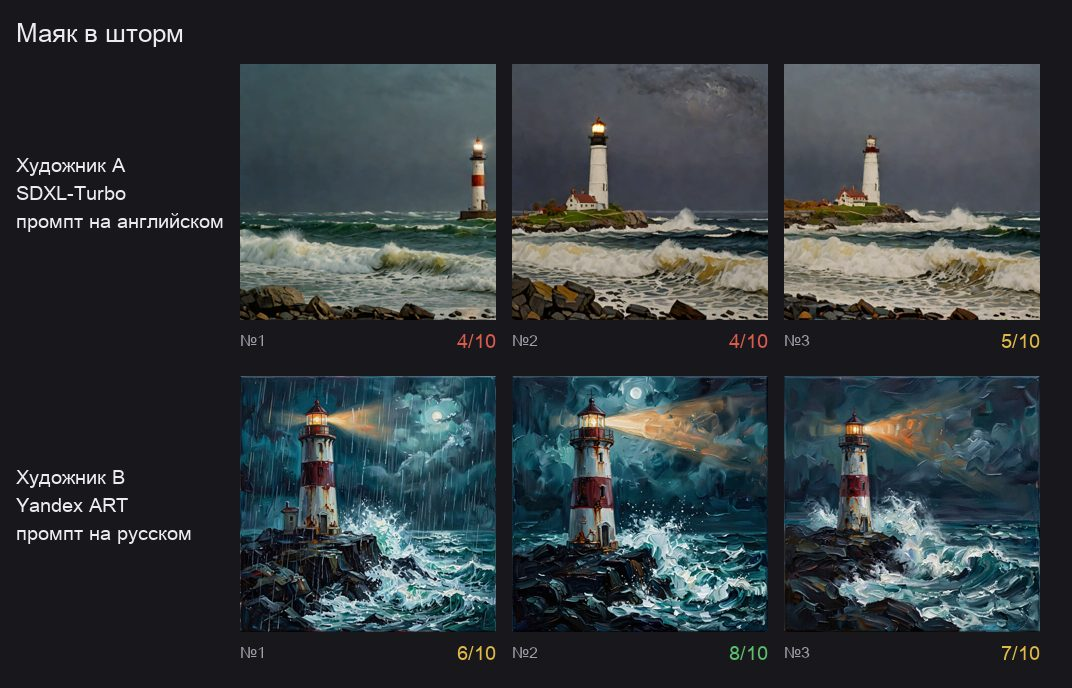

In [12]:
for sheet in sorted(RUNS.glob("*/0*/evolution.png"))[:6]:
    show(sheet)

## Как воспроизвести

```bash
bash experiments/culture_language.sh                       # культурная асимметрия
bash experiments/proverbs.sh                               # «Нейро-Крокодил»
bash experiments/telephone.sh                              # «Испорченный телефон»
agent-artist-experiment run --idea "Маяк в шторм" --repeats 3 --iterations 3   # shared против isolated
```